# 01 · Data audit: dead meters, stuck meters and building scope

**Question:** which of the 20 BDG2 office buildings have meter data good enough to model, and which hours must be
treated as missing?

**Why first:** a model's error is only meaningful on real consumption. An office reading exactly 0 kWh for months is
a meter fault, and predicting zero for it is easy, so faulty meters make the metrics look better than they are.

Outcome (details below, decision **D-001** in `docs/decisions.md`): **12 buildings modelled, 8 excluded**, and
zero or stuck hours inside the 12 are masked as missing rather than deleted or imputed.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from energy.quality import building_scope, completeness, dead_meters, flat_runs, invalid_mask, zero_share_by_month

FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
BLUE, ORANGE, GRAY = "#257de0", "#f47230", "#666666"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e6", "axes.edgecolor": "#999999"})
pd.set_option("display.width", 200)

df = pd.read_parquet(ROOT / "data" / "historical_consumption.parquet")
df["timestamp"] = pd.to_datetime(df["timestamp"])
df = df.sort_values(["building_id", "timestamp"]).reset_index(drop=True)
print(f"{len(df):,} rows · {df['building_id'].nunique()} buildings · {df['timestamp'].min()} to {df['timestamp'].max()}")

350,880 rows · 20 buildings · 2016-01-01 00:00:00 to 2017-12-31 23:00:00


## 1. Completeness

Every building has all 17,544 hours (2 × 8,760 + the leap day) and no null readings. That looks perfect, which is
the warning sign: gaps have been **filled**, with zeros or with constant values, either in BDG2's raw file or in
the Colab preprocessing. Sections 2 and 3 find them.

In [2]:
comp = completeness(df)
print(comp[["rows", "expected", "missing_hours", "null_readings"]].describe().loc[["min", "max"]])
print("duplicate (building, hour) keys:", int(df.duplicated(["building_id", "timestamp"]).sum()))
print("negative readings:", int((df["consumption"] < 0).sum()))

        rows  expected  missing_hours  null_readings
min  17544.0   17544.0            0.0            0.0
max  17544.0   17544.0            0.0            0.0
duplicate (building, hour) keys: 0
negative readings: 0


## 2. Zero readings by month (dead meters)

8 buildings have at least one month with >= 90 % zero hours:
building_id
Hog_office_Alisha        6
Shrew_office_Doris      11
Shrew_office_Doug       11
Shrew_office_Kenneth    11
Shrew_office_Lin        11
Shrew_office_Nora       11
Shrew_office_Rose        9
Shrew_office_Sherill    11


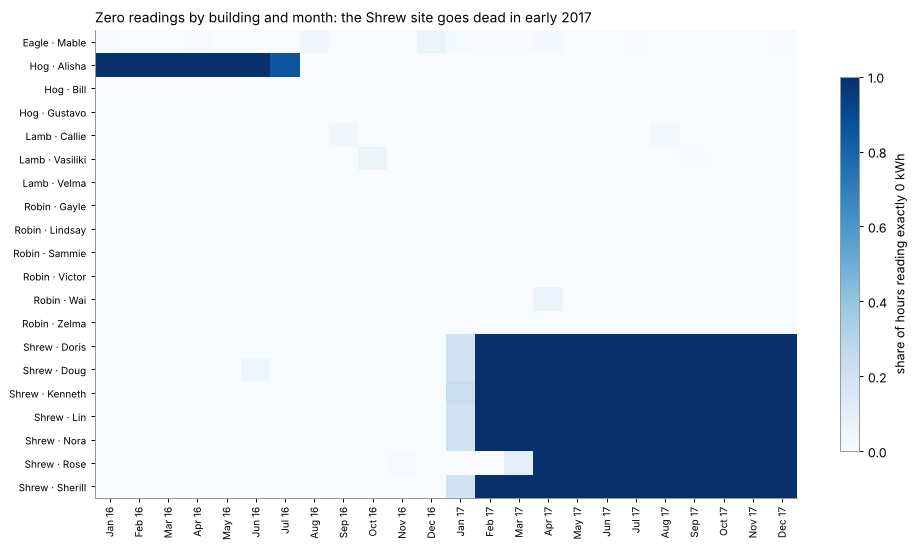

In [3]:
z = zero_share_by_month(df)
fig, ax = plt.subplots(figsize=(11, 6.2))
im = ax.imshow(z.values, aspect="auto", cmap="Blues", vmin=0, vmax=1)
ax.set_yticks(range(len(z.index)), [b.replace("_office_", " · ") for b in z.index], fontsize=8)
ax.set_xticks(range(len(z.columns)), [p.strftime("%b %y") for p in z.columns], rotation=90, fontsize=8)
ax.grid(False)
cb = fig.colorbar(im, ax=ax, shrink=0.8)
cb.set_label("share of hours reading exactly 0 kWh")
ax.set_title("Zero readings by building and month: the Shrew site goes dead in early 2017", loc="left", fontsize=11)
fig.tight_layout()
fig.savefig(FIG / "zero_share_heatmap.png", bbox_inches="tight")
plt.show()

flagged = dead_meters(df, threshold=0.9)
print(f"{len(flagged)} buildings have at least one month with >= 90 % zero hours:")
print((z >= 0.9).sum(axis=1).loc[flagged].rename("months_>=90%_zero").to_string())

The rule from the plan (`zero share ≥ 0.9 in a month`) flags **8** buildings, not 7. They are two different faults:

- **7 Shrew buildings:** live through 2016, then read zero from late January 2017 (Rose from March) to the end of the
  data. No usable 2017 data, and 2017 is the year every model is evaluated on.
- **Hog_office_Alisha:** reads zero from 1 January to late July 2016, then is live. The meter started late. Its zeros
  are masked; the building stays.

The first dead hour per building:

In [4]:
def first_hour_of_last_zero_run(s: pd.Series) -> pd.Timestamp | None:
    nonzero = s[s.ne(0)]
    return None if nonzero.index.max() == s.index.max() else nonzero.index.max() + pd.Timedelta("1h")

for b in flagged:
    s = df[df["building_id"] == b].set_index("timestamp")["consumption"]
    live = s[s.ne(0)]
    print(f"{b:22s} first non-zero {live.index.min()}  last non-zero {live.index.max()}  zero hours {int(s.eq(0).sum()):5d}")

Hog_office_Alisha      first non-zero 2016-07-27 11:00:00  last non-zero 2017-12-31 23:00:00  zero hours  5003
Shrew_office_Doris     first non-zero 2016-01-01 00:00:00  last non-zero 2017-01-25 23:00:00  zero hours  8160
Shrew_office_Doug      first non-zero 2016-01-01 00:00:00  last non-zero 2017-01-25 23:00:00  zero hours  8193
Shrew_office_Kenneth   first non-zero 2016-01-01 00:00:00  last non-zero 2017-01-24 23:00:00  zero hours  8184
Shrew_office_Lin       first non-zero 2016-01-01 00:00:00  last non-zero 2017-01-25 23:00:00  zero hours  8162
Shrew_office_Nora      first non-zero 2016-01-01 00:00:00  last non-zero 2017-01-25 23:00:00  zero hours  8160
Shrew_office_Rose      first non-zero 2016-01-01 00:00:00  last non-zero 2017-03-29 00:00:00  zero hours  6677
Shrew_office_Sherill   first non-zero 2016-01-01 00:00:00  last non-zero 2017-01-25 23:00:00  zero hours  8160


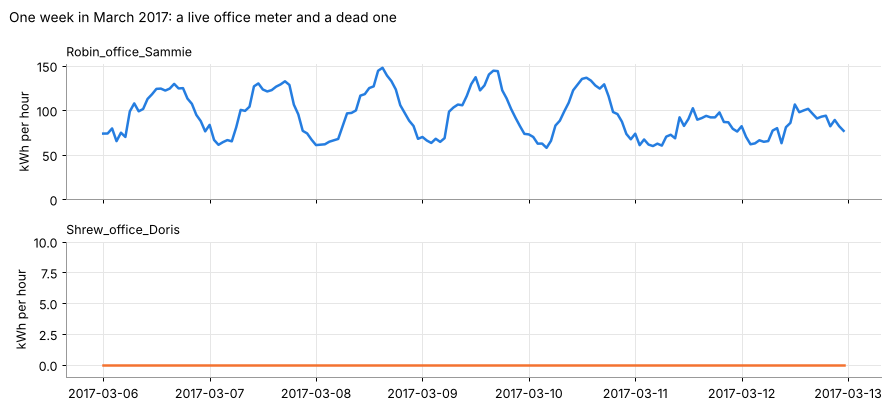

In [5]:
week = slice("2017-03-06", "2017-03-12 23:00")
fig, axes = plt.subplots(2, 1, figsize=(10, 4.6), sharex=True)
for ax, b, color in [(axes[0], "Robin_office_Sammie", BLUE), (axes[1], "Shrew_office_Doris", ORANGE)]:
    s = df[df["building_id"] == b].set_index("timestamp").loc[week, "consumption"]
    ax.plot(s.index, s.values, color=color, lw=2)
    ax.set_title(b, loc="left", fontsize=10)
    ax.set_ylabel("kWh per hour")
    ax.set_ylim(bottom=0)
axes[1].set_ylim(-1, 10)
fig.suptitle("One week in March 2017: a live office meter and a dead one", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
fig.savefig(FIG / "live_vs_dead_week.png", bbox_inches="tight")
plt.show()

## 3. Stuck meters and filled gaps

A real office meter changes every hour. A **non-zero value repeated for 24 hours or more** is a stuck meter or a
gap filled with a constant. Shorter repeats are kept: Eagle's meter reports two decimals, so a few identical night
hours are plausible.

In [6]:
fr = flat_runs(df, min_run=24)
print(fr[fr["flat_runs"] > 0].sort_values("flat_hours", ascending=False).to_string())

                      flat_runs  flat_hours  longest_run
building_id                                             
Robin_office_Lindsay         12        5992         5195
Lamb_office_Callie            4        5252         3119
Lamb_office_Velma             5        3403         2183
Lamb_office_Vasiliki          3        3285         2183
Robin_office_Victor          15        2696         1091
Robin_office_Gayle           16        2570         1091
Robin_office_Sammie           4        1677         1043
Robin_office_Zelma            4        1677         1043
Robin_office_Wai             10         334           94
Shrew_office_Rose             1         118          118
Eagle_office_Mable            2         103           79


The Robin buildings share the same flat dates (for example 6–14 Jan 2016, 8 Mar–20 Apr 2016, 26 Jul–10 Aug 2016,
11–20 Dec 2017), so these are site-wide outages that were filled, not six independent faults. The longest is
Robin_office_Lindsay: one value, 3.94 kWh, for 5,195 hours (March to October 2016), against a typical 45 kWh.
Lamb_office_Callie reads a constant 0.0007 kWh from 24 August 2017 to the end of the data, which is the whole test
period.

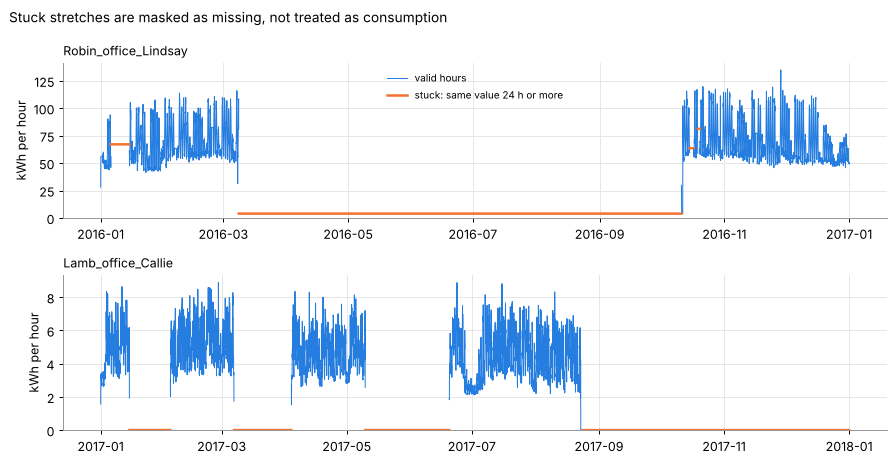

In [7]:
flags = invalid_mask(df)
fig, axes = plt.subplots(2, 1, figsize=(10, 5.2))
for ax, b, span in [(axes[0], "Robin_office_Lindsay", slice("2016-01-01", "2016-12-31")),
                    (axes[1], "Lamb_office_Callie", slice("2017-01-01", "2017-12-31"))]:
    rows = df["building_id"].eq(b)
    s = df[rows].set_index("timestamp")["consumption"].loc[span]
    bad = flags.loc[rows, "stuck"].set_axis(df.loc[rows, "timestamp"]).loc[span]
    ax.plot(s.index, s.where(~bad).values, color=BLUE, lw=0.8, label="valid hours")
    ax.plot(s.index, s.where(bad).values, color=ORANGE, lw=2, label="stuck: same value 24 h or more")
    ax.set_title(b, loc="left", fontsize=10)
    ax.set_ylabel("kWh per hour")
    ax.set_ylim(bottom=0)
axes[0].legend(frameon=False, fontsize=8, loc="upper center")
fig.suptitle("Stuck stretches are masked as missing, not treated as consumption", x=0.01, ha="left", fontsize=11)
fig.tight_layout()
fig.savefig(FIG / "stuck_meter_examples.png", bbox_inches="tight")
plt.show()

## 4. Building scope

Rule (D-001): an hour is **invalid** if it reads exactly zero (BDG2's own cleaned file removes zero electricity
readings for the same reason) or belongs to a run of 24+ identical non-zero readings. A building is **modelled** if at
least 50 % of its 2017 hours are valid. Invalid hours inside modelled buildings are masked: they never count as a
training target or a test actual.

In [8]:
scope = building_scope(df, eval_year=2017)
print(scope.round(3).sort_values("valid_share_2017").to_string())
out = scope.round(4).reset_index()
out.to_csv(ROOT / "reports" / "data_quality_summary.csv", index=False)
modelled = sorted(scope.index[scope["modelled"]])
excluded = sorted(scope.index[~scope["modelled"]])
print(f"\nmodelled: {len(modelled)} · excluded: {len(excluded)} -> {excluded}")
inside = df["building_id"].isin(modelled)
print(f"invalid hours masked inside the {len(modelled)} modelled buildings: "
      f"{int(flags.loc[inside, 'invalid'].sum()):,} of {int(inside.sum()):,} ({flags.loc[inside, 'invalid'].mean():.1%})")

                      hours  zero_hours  stuck_hours  valid_share  valid_share_2017  modelled
building_id                                                                                  
Shrew_office_Kenneth  17544        8184            0        0.534             0.066     False
Shrew_office_Doris    17544        8160            0        0.535             0.068     False
Shrew_office_Doug     17544        8193            0        0.533             0.068     False
Shrew_office_Lin      17544        8162            0        0.535             0.068     False
Shrew_office_Nora     17544        8160            0        0.535             0.068     False
Shrew_office_Sherill  17544        8160            0        0.535             0.068     False
Shrew_office_Rose     17544        6677          118        0.613             0.238     False
Lamb_office_Callie    17544          45         5252        0.698             0.398     False
Lamb_office_Velma     17544           2         3403        

## 5. How much the faults flattered the prototype

The prototype's test predictions (`dashboard_exports/predictions.csv`, last 20 % of each building, from 9 Aug 2017)
scored on all 20 buildings, and then only on valid hours of the 12 modelled ones. The persistence baseline ("same as
last hour") is scored on exactly the same rows.

In [9]:
pred = pd.read_csv(ROOT / "dashboard_exports" / "predictions.csv", parse_dates=["timestamp"])
d = df.assign(valid=~flags["invalid"], persistence=df.groupby("building_id")["consumption"].shift(1))
m = pred.merge(d[["building_id", "timestamp", "valid", "persistence"]], on=["building_id", "timestamp"])

def score(rows: pd.DataFrame, name: str) -> dict:
    y = rows["actual_consumption"]
    e_model, e_pers = (y - rows["predicted_consumption"]).abs(), (y - rows["persistence"]).abs()
    return {"rows": name, "n": len(rows), "model_MAE": e_model.mean(), "model_WAPE_%": 100 * e_model.sum() / y.sum(),
            "persistence_WAPE_%": 100 * e_pers.sum() / y.sum()}

table = pd.DataFrame([
    score(m, "all 20 buildings (README today)"),
    score(m[m["building_id"].isin(modelled)], "12 modelled buildings, all hours"),
    score(m[m["building_id"].isin(modelled) & m["valid"]], "12 modelled buildings, valid hours"),
]).round(3)
print(table.to_string(index=False))
print(f"\nShrew test rows: {int(m['building_id'].str.startswith('Shrew').sum()):,} "
      f"({m['building_id'].str.startswith('Shrew').mean():.0%} of the test set), every one an actual of 0 kWh")

                              rows     n  model_MAE  model_WAPE_%  persistence_WAPE_%
   all 20 buildings (README today) 69520      3.573         3.492               5.545
  12 modelled buildings, all hours 41712      4.974         2.917               5.543
12 modelled buildings, valid hours 40914      5.011         2.902               5.577

Shrew test rows: 24,332 (35% of the test set), every one an actual of 0 kWh


Removing the dead meters moves the two metrics in opposite directions. **MAE rises** from 3.57 to 5.01 kWh,
because a third of the test set was a free zero. **WAPE falls** from 3.49 % to 2.90 %, because the model's small
non-zero guesses on dead meters added error to the numerator and nothing to the denominator. Either way, the
README's headline was not measuring the buildings that matter. The model still roughly halves the error of
persistence (2.90 % vs 5.58 %). Week 5 retrains on the cleaned scope instead of rescoring old predictions.

## 6. Optional: where did the zeros and flat values come from?

The README of BDG2's cleaned meter file says zero electricity readings were removed (left missing) and no gaps were
filled. If the raw file also has missing values where this parquet has zeros or constants, the filling happened in
the Colab preprocessing. To check, download `data/meters/raw/electricity.csv` (about 175 MB) from the BDG2 GitHub
repository into `data/raw/` and run the cell below. It is skipped when the file is absent.

In [10]:
raw_path = ROOT / "data" / "raw" / "electricity.csv"
if raw_path.exists():
    raw = pd.read_csv(raw_path, usecols=["timestamp", *sorted(set(df["building_id"]))], parse_dates=["timestamp"])
    raw = raw.melt(id_vars="timestamp", var_name="building_id", value_name="raw")
    j = df.merge(raw, on=["building_id", "timestamp"], how="left").join(flags)
    for kind in ("zero", "stuck"):
        part = j[j[kind]]
        print(f"{kind:5s} hours: {len(part):6,} · raw is NaN in {part['raw'].isna().mean():.0%} · "
              f"raw equals ours in {(part['raw'] == part['consumption']).mean():.0%}")
else:
    print(f"skipped: {raw_path.relative_to(ROOT)} not found (see data/README.md for the download step)")

skipped: data/raw/electricity.csv not found (see data/README.md for the download step)


## Conclusions → D-001

1. **Exclude 8 buildings from modelling:** the 7 Shrew buildings (dead from early 2017) and Lamb_office_Callie (stuck
   at 0.0007 kWh for the whole test period). Keep them in this notebook as the data-quality case study.
2. **Model 12 buildings.** Mask zero readings and 24 h+ stuck runs as missing in all of them; do not impute.
3. Hog_office_Alisha's first seven months are masked (late meter start), not a reason to drop the building.
4. Still open: whether the zeros and flat values are in BDG2's raw file or came from the Colab preprocessing
   (section 6).